Análise dos dados - E-commerce de Roupas

Estatisticas Descritivas:
             Nota  N_Avaliações    Desconto       Preço
count  295.000000    295.000000  295.000000  295.000000
mean     4.480678    490.511864   16.013559  130.836644
std      0.321243   1079.395818    9.928305   64.232780
min      2.300000      3.000000    5.000000   25.630000
25%      4.300000     19.000000    9.000000   73.340000
50%      4.500000     77.000000   11.000000  129.210000
75%      4.700000    326.000000   22.000000  179.900000
max      5.000000   9077.000000   51.000000  326.550000


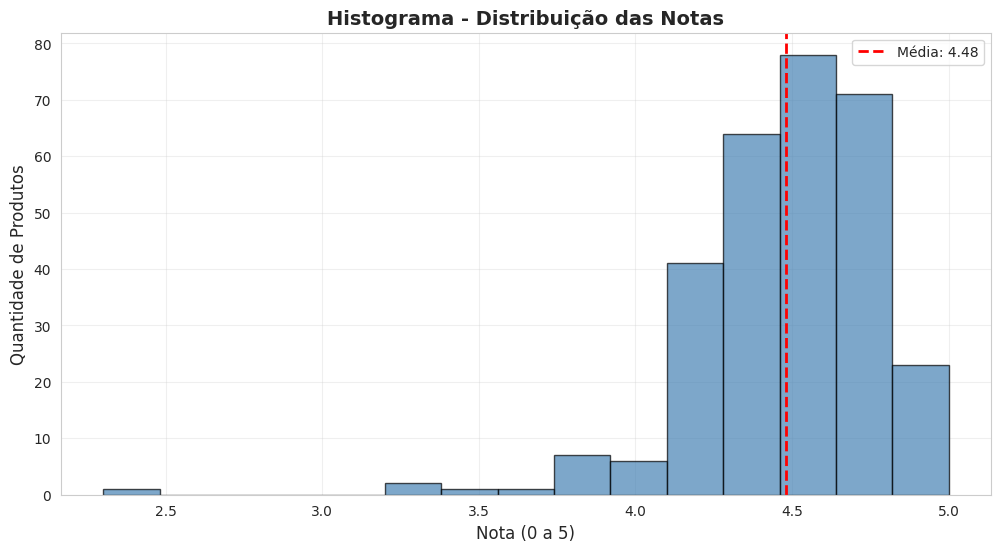

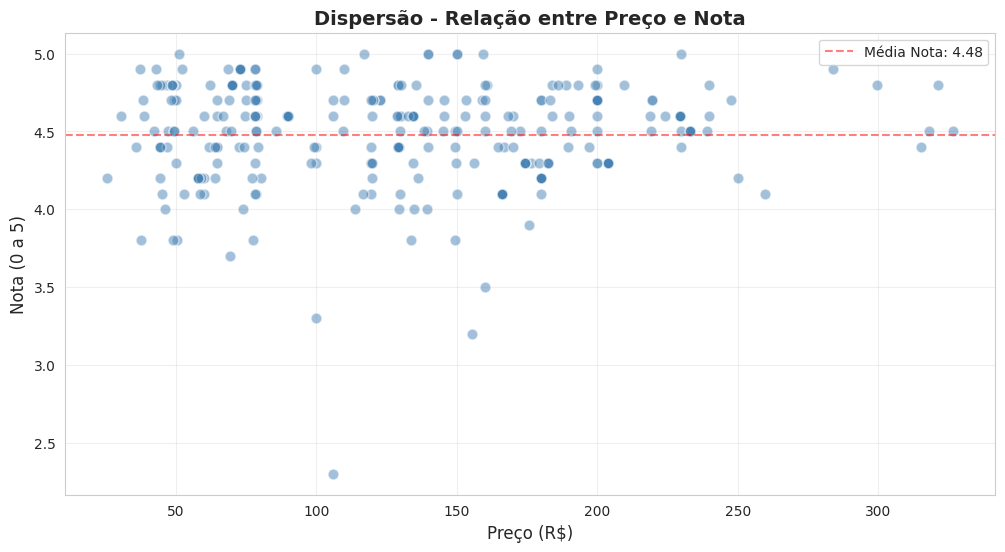

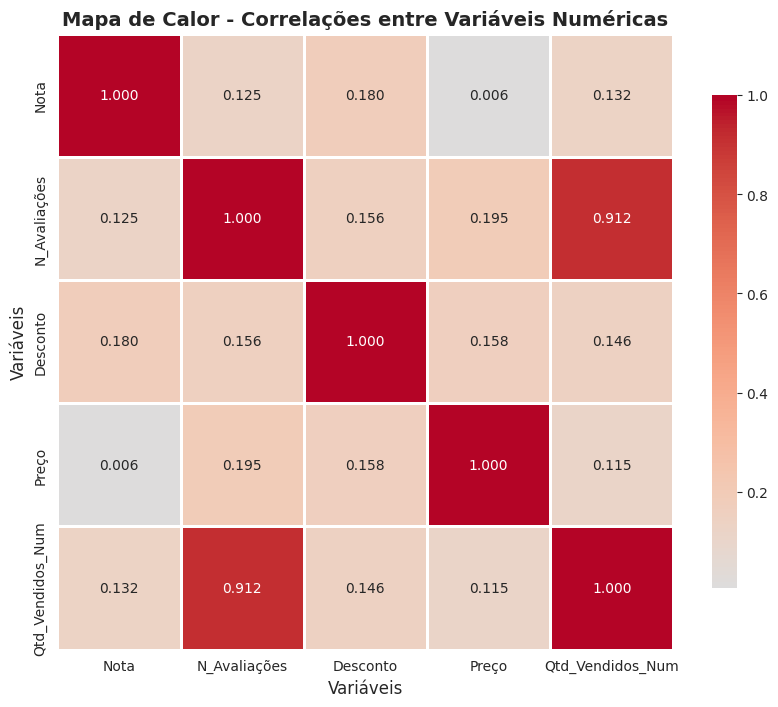

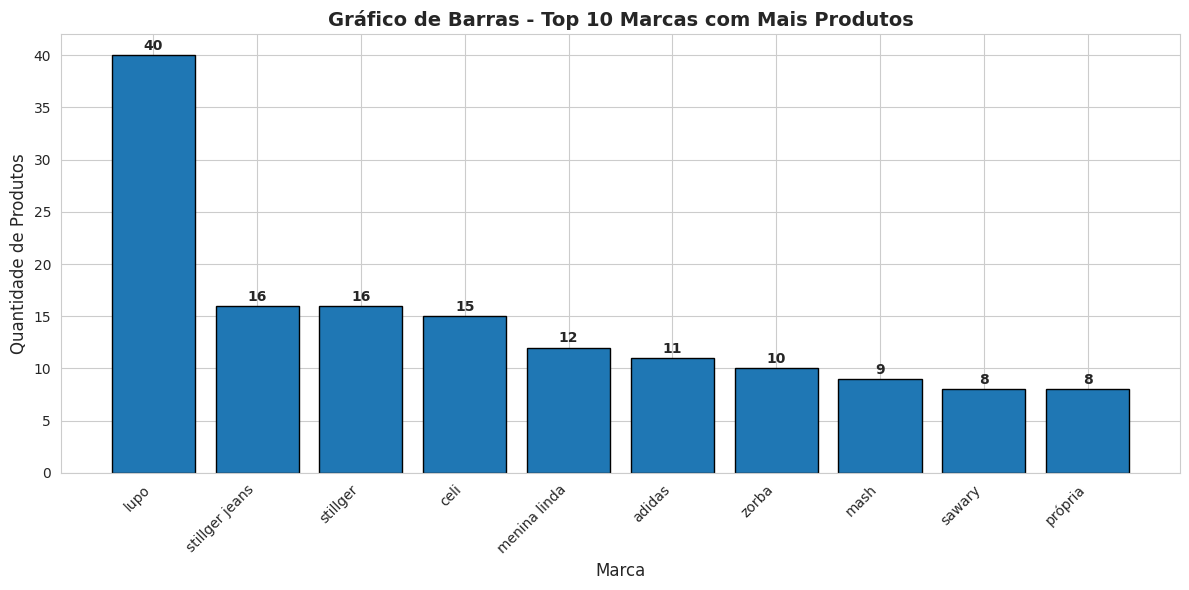

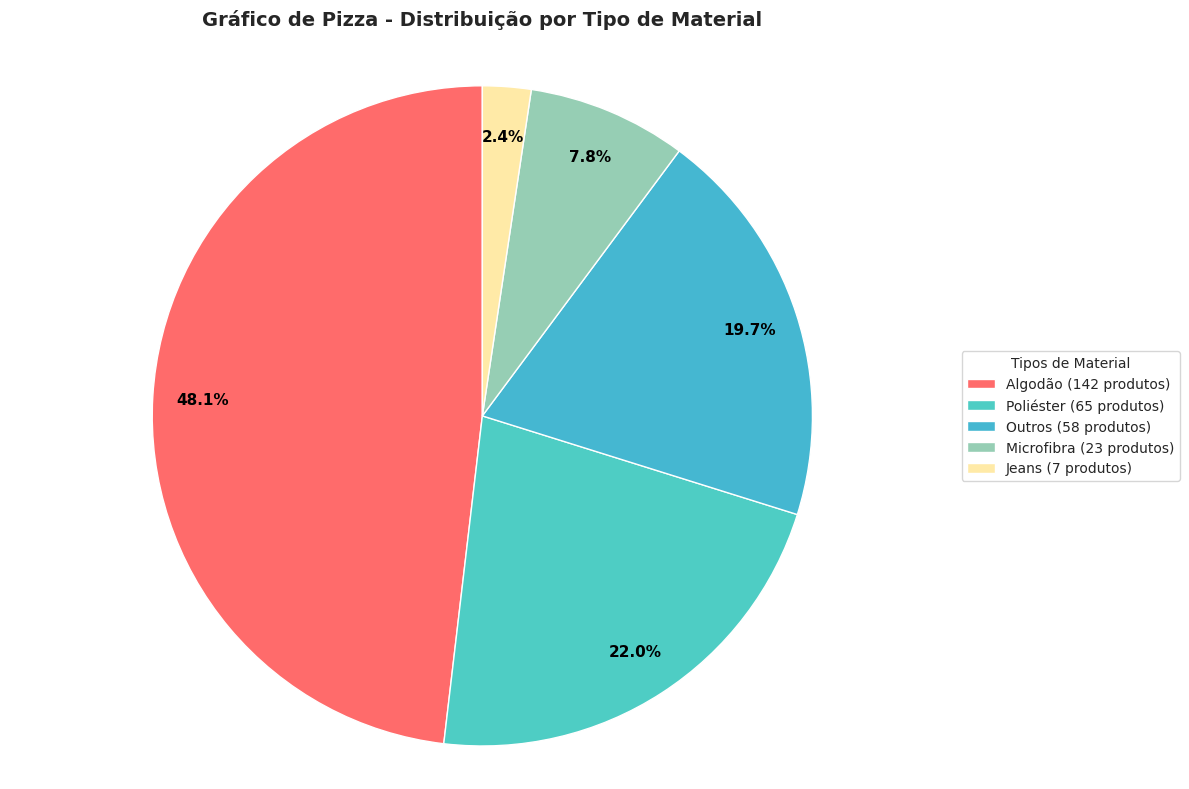

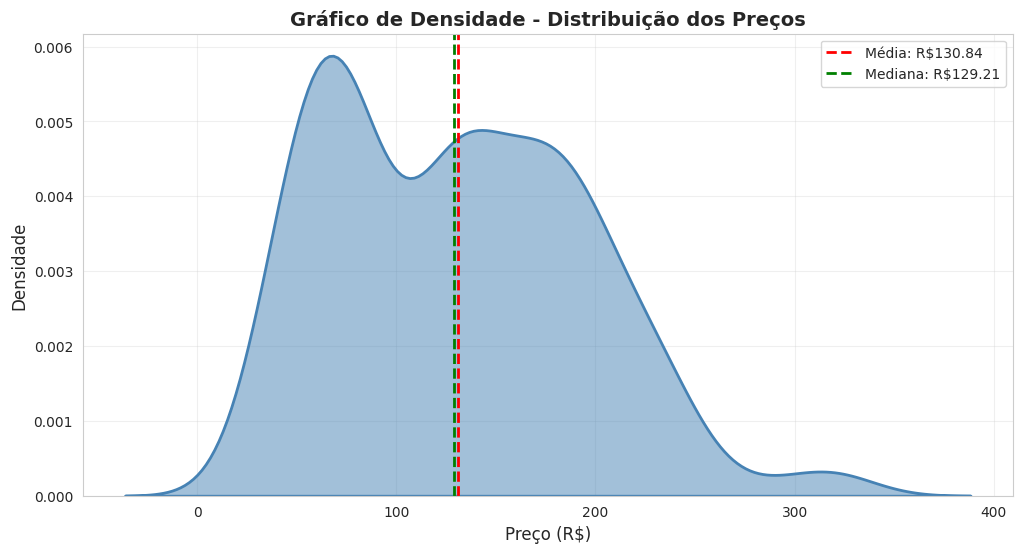

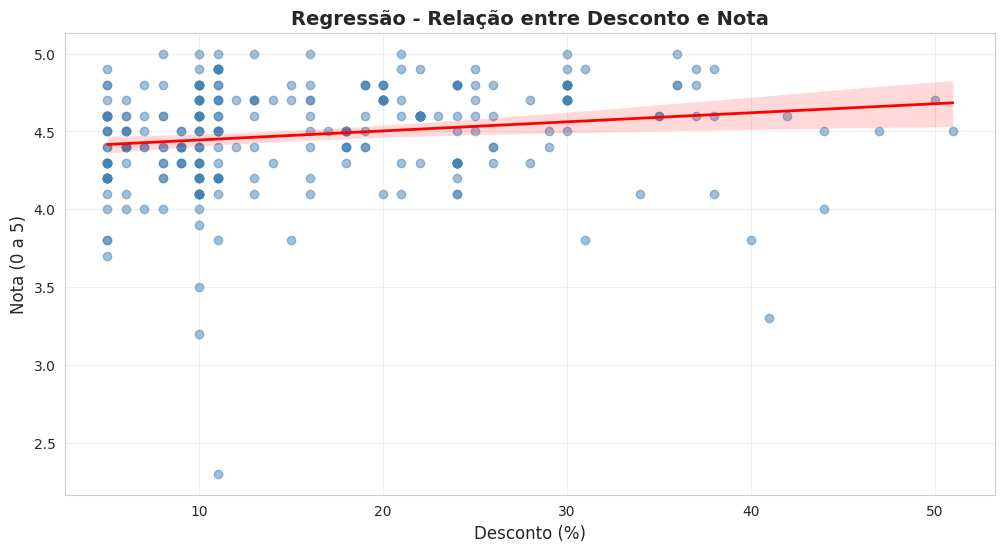


PRINCIPAIS INSIGHTS DA ANÁLISE

1. NOTA MÉDIA GERAL: 4.48/5.0
   -> 172 produtos tem nota acima de 4.5

2. PREÇO MÉDIO: R$130.84
   -> Produto mais caro: R$326.55
   -> Produto mais barato: R$25.63

3. DESCONTO MÉDIO: 16.0%
   -> 22 produtos tem desconto acima de 30%

4. MATERIAL MAIS COMUM: Algodão
   -> Melhor nota por material: Algodão

5. MARCA COM MAIS PRODUTOS: lupo (40 produtos)

6. GÊNERO DOMINANTE: Masculino


In [15]:
# Projeto de Análise de Dados - E-commerce e Estatistica
# ======================================================

# Bibliotecas necessárias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração dos gráficos
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Leia o arquivo dentro de um dataframe
df = pd.read_csv('ecommerce_estatistica.csv')

# Remover coluna 'Unnamed: 0'
df = df.drop('Unnamed: 0', axis=1)

# 2. Análise detalhada dos dados
print("Análise dos dados - E-commerce de Roupas")
print("="*60)

print("\nEstatisticas Descritivas:")
print(df[['Nota', 'N_Avaliações', 'Desconto', 'Preço']].describe())

# Colunas auxiliares
df['Qtd_Vendidos_Num'] = df['Qtd_Vendidos'].astype(str).str.replace('+', '')
df['Qtd_Vendidos_Num'] = df['Qtd_Vendidos_Num'].str.replace('mil', '000')
df['Qtd_Vendidos_Num'] = pd.to_numeric(df['Qtd_Vendidos_Num'], errors='coerce')

# Materiais em poucas categorias
df['Material_Agrupado'] = df['Material'].apply(lambda x:
    'Algodão' if 'algodão' in str(x).lower() else
    'Poliéster' if 'poliéster' in str(x).lower() else
    'Microfibra' if 'microfibra' in str(x).lower() else
    'Jeans' if any(w in str(x).lower() for w in ['Jeans', 'brim', 'sarja']) else
    'Outros')

# 1. Histograma
plt.figure(figsize=(12, 6))
plt.hist(df['Nota'].dropna(), bins=15, edgecolor='black', alpha=0.7, color='steelblue')
plt.axvline(df['Nota'].mean(), color='red', linestyle='--', linewidth=2, label=f'Média: {df["Nota"].mean():.2f}')
plt.title('Histograma - Distribuição das Notas', fontsize=14, fontweight='bold')
plt.xlabel('Nota (0 a 5)', fontsize=12)
plt.ylabel('Quantidade de Produtos', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. DISPERSÃO
plt.figure(figsize=(12, 6))
plt.scatter(df['Preço'], df['Nota'], alpha=0.5, c='steelblue', edgecolors='white', s=60)
plt.title('Dispersão - Relação entre Preço e Nota', fontsize=14, fontweight='bold')
plt.xlabel('Preço (R$)', fontsize=12)
plt.ylabel('Nota (0 a 5)', fontsize=12)
plt.axhline(df['Nota'].mean(), color='red', linestyle='--', alpha=0.5, label=f'Média Nota: {df["Nota"].mean():.2f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. MAPA DE CALOR
plt.figure(figsize=(10, 8))
variaveis_correlacao = ['Nota', 'N_Avaliações', 'Desconto', 'Preço', 'Qtd_Vendidos_Num']
corr_matrix = df[variaveis_correlacao].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.3f', square=True,
            linewidths=1, cbar_kws={'shrink': 0.8})
plt.title('Mapa de Calor - Correlações entre Variáveis Numéricas', fontsize=14, fontweight='bold')
plt.xlabel('Variáveis', fontsize=12)
plt.ylabel('Variáveis', fontsize=12)
plt.show()

# 4. GRÁFICO DE BARRA
plt.figure(figsize=(12, 6))
top_marcas = df['Marca'].value_counts().head(10)
cores_barra = ['#1f77b4']
bars = plt.bar(range(len(top_marcas)), top_marcas.values, color=cores_barra[:len(top_marcas)], edgecolor='black')
plt.title('Gráfico de Barras - Top 10 Marcas com Mais Produtos', fontsize=14, fontweight='bold')
plt.xlabel('Marca', fontsize=12)
plt.ylabel('Quantidade de Produtos', fontsize=12)
plt.xticks(range(len(top_marcas)), top_marcas.index, rotation=45, ha='right')
for i, v in enumerate(top_marcas.values):
    plt.text(i, v + 0.5, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# 5. GRÁFICO DE PIZZA
plt.figure(figsize=(12, 8))

material_counts = df['Material_Agrupado'].value_counts()
cores_pizza = ['#ff6b6b', '#4ecdc4', '#45b7d1', '#96ceb4', '#ffeaa7']

wedges, texts, autotexts = plt.pie(
    material_counts.values,
    labels=None,
    autopct='%1.1f%%',
    startangle=90,
    colors=cores_pizza[:len(material_counts)],
    textprops={'fontsize': 11, 'fontweight': 'bold'},
    pctdistance=0.85
)

for autotext in autotexts:
    autotext.set_color('black')
    autotext.set_fontsize(11)
    autotext.set_fontweight('bold')

# Legenda lateral
plt.legend(
    wedges,
    [f'{label} ({count} produtos)' for label, count in zip(material_counts.index, material_counts.values)],
    title="Tipos de Material",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1),
    fontsize=10
)

plt.title('Gráfico de Pizza - Distribuição por Tipo de Material', fontsize=14, fontweight='bold', pad=20)
plt.axis('equal')
plt.tight_layout()
plt.show()

# 6. GRÁFICO DE DENSIDADE
plt.figure(figsize=(12, 6))
sns.kdeplot(df['Preço'], fill=True, color='steelblue', alpha=0.5, linewidth=2)
plt.axvline(df['Preço'].mean(), color='red', linestyle='--', linewidth=2, label=f'Média: R${df["Preço"].mean():.2f}')
plt.axvline(df['Preço'].median(), color='green', linestyle='--', linewidth=2, label=f'Mediana: R${df["Preço"].median():.2f}')
plt.title('Gráfico de Densidade - Distribuição dos Preços', fontsize=14, fontweight='bold')
plt.xlabel('Preço (R$)', fontsize=12)
plt.ylabel('Densidade', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 7. GRÁFICO DE REGRESSÃO
plt.figure(figsize=(12, 6))
sns.regplot(x='Desconto', y='Nota', data=df,
            scatter_kws={'alpha':0.5, 'color':'steelblue'},
            line_kws={'color':'red', 'linewidth':2})
plt.title('Regressão - Relação entre Desconto e Nota', fontsize=14, fontweight='bold')
plt.xlabel('Desconto (%)', fontsize=12)
plt.ylabel('Nota (0 a 5)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

# ANÁLISE FINAL
print("\n" + "="*60)
print("PRINCIPAIS INSIGHTS DA ANÁLISE")
print("="*60)

print(f"\n1. NOTA MÉDIA GERAL: {df['Nota'].mean():.2f}/5.0")
print(f"   -> {len(df[df['Nota'] >= 4.5])} produtos tem nota acima de 4.5")

print(f"\n2. PREÇO MÉDIO: R${df['Preço'].mean():.2f}")
print(f"   -> Produto mais caro: R${df['Preço'].max():.2f}")
print(f"   -> Produto mais barato: R${df['Preço'].min():.2f}")

print(f"\n3. DESCONTO MÉDIO: {df['Desconto'].mean():.1f}%")
print(f"   -> {len(df[df['Desconto'] > 30])} produtos tem desconto acima de 30%")

print(f"\n4. MATERIAL MAIS COMUM: {df['Material_Agrupado'].mode()[0]}")
print(f"   -> Melhor nota por material: {material_counts.index[0]}")

print(f"\n5. MARCA COM MAIS PRODUTOS: {top_marcas.index[0]} ({top_marcas.values[0]} produtos)")

print(f"\n6. GÊNERO DOMINANTE: {df['Gênero'].value_counts().index[0]}")